In [ ]:
# ============================================================
# PART 0 – Kurulum, Import'lar ve Temel Yardımcı Fonksiyonlar
# ============================================================
# Bu partta:
# - Gerekli paketleri yüklüyoruz
# - Kütüphaneleri import ediyoruz
# - Reprodüksiyon için SEED sabitliyoruz
# - Görüntü/mask okuma ve basit ön-işleme fonksiyonlarını tanımlıyoruz

!pip install opencv-python scikit-image py7zr --quiet

import os
import glob
import random
import zipfile
from typing import List, Tuple

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Reprodüksiyon için seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Görüntü boyutu ve kanal sayıları
IMG_HEIGHT = 256
IMG_WIDTH  = 256
IMG_CHANNELS_RGB    = 3
IMG_CHANNELS_HYBRID = 4  # RGB + coarse mask

# ------------------------------------------------------------
# Temel okuma fonksiyonları
# ------------------------------------------------------------

def read_image(path: str) -> np.ndarray:
    """
    JPEG dermoskopik görüntüyü:
      - BGR'den RGB'ye çevirir
      - 256x256'e yeniden boyutlandırır (bilinear)
      - [0-255] uint8 RGB olarak döndürür
    """
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"Image not found: {path}")
    bgr = cv2.resize(bgr, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_LINEAR)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    return rgb

def read_mask(path: str) -> np.ndarray:
    """
    PNG ground-truth maskeyi:
      - 256x256'e yeniden boyutlandırır (NEAREST, bozulmasın)
      - 0/1 binary float maske (float32) olarak döndürür
    """
    mask = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Mask not found: {path}")
    mask = cv2.resize(mask, (IMG_WIDTH, IMG_HEIGHT), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)  # 0 veya 1
    return mask

# ------------------------------------------------------------
# Basit (ve artık "full") ön-işleme wrapper fonksiyonları
# ------------------------------------------------------------

def hair_removal_simple(img_rgb_uint8: np.ndarray) -> np.ndarray:
    """
    Eski placeholder saç giderme fonksiyonu.
    Artık gerçek saç giderme PART 6'daki preprocess_image_full içinde
    yapıldığı için bu fonksiyonu projede kullanmıyoruz.
    Geriye dönük uyumluluk için bırakıldı.
    """
    return img_rgb_uint8.copy()

def preprocess_rgb(rgb_image_uint8: np.ndarray) -> np.ndarray:
    """
    *** ANA ÖN-İŞLEME FONKSİYONU ***
    Sunumdaki tam pipeline'a karşılık gelir:

      1) Gray-World color constancy
      2) Black-hat + inpainting ile saç giderme
      3) Lab(L) kanalında CLAHE
      4) (Opsiyonel) Gaussian blur
      5) [0,1] normalizasyon
      6) (Opsiyonel) gamma düzeltmesi

    Girdi : [0-255] uint8 RGB (H,W,3)
    Çıktı : [0,1] float32 RGB (H,W,3) – tam ön-işlenmiş görüntü

    NOT:
      preprocess_image_full fonksiyonu PART 6'da tanımlıdır.
      Bu hücreyi çalıştırdıktan sonra PART 6'yı da çalıştırman gerekir;
      ama genelde "Runtime -> Run all" yaptığın için sırayla zaten çalışır.
    """
    # PART 6'da tanımlanan fonksiyonu kullanıyoruz
    img_pre, hair_mask = preprocess_image_full(
        img_rgb_uint8=rgb_image_uint8,
        use_color_constancy=True,
        use_hair_removal=True,
        clahe_clip_limit=2.0,
        clahe_tile_grid=(8, 8),
        gaussian_ksize=3,   # hafif blur
        gaussian_sigma=0,
        gamma=1.0
    )
    return img_pre

def preprocess_mask(mask_image_float: np.ndarray) -> np.ndarray:
    """
    Maske read_mask ile zaten 0/1 float32 olarak geliyor.
    Ek bir işleme gerek yok; şimdilik direkt geri döndürüyoruz.
    """
    return mask_image_float


In [ ]:
# ============================================================
# PART 1 – Drive mount + MyDrive içeriği + ZIP dosyalarını bul
# ============================================================
# Bu partta:
# - Google Drive'ı Colab'e bağlıyoruz
# - MyDrive içeriğini listeliyoruz (doğru klasörde miyiz bakmak için)
# - ISIC 2016 train image ve mask zip dosyalarını recursive arıyoruz

from google.colab import drive
import py7zr  # PART 0'da yüklendi

drive.mount('/content/drive')

MYDRIVE_ROOT = "/content/drive/MyDrive"

print("MyDrive içerisinden bir liste:")
!ls "/content/drive/MyDrive"

# ------------------------------------------------------------
# ZIP dosyalarını recursive şekilde ara
# ------------------------------------------------------------

def find_first(patterns):
    """
    Verilen pattern listesi içinde ilk bulunan dosyanın path'ini döndürür.
    Hiçbiri yoksa None döner.
    """
    for pat in patterns:
        files = glob.glob(pat, recursive=True)
        if files:
            return files[0]
    return None

train_img_patterns = [
    os.path.join(MYDRIVE_ROOT, "**", "*Training_Data*.zip"),
    os.path.join(MYDRIVE_ROOT, "**", "ISBI2016_ISIC_Part1_Training_Data*.zip"),
]

train_gt_patterns = [
    os.path.join(MYDRIVE_ROOT, "**", "*Training_GroundTruth*.zip"),
    os.path.join(MYDRIVE_ROOT, "**", "ISBI2016_ISIC_Part1_Training_GroundTruth*.zip"),
]

TRAIN_IMG_ARCHIVE = find_first(train_img_patterns)
TRAIN_GT_ARCHIVE  = find_first(train_gt_patterns)

print("\nBulunan arşiv dosyaları:")
print("  TRAIN_IMG_ARCHIVE:", TRAIN_IMG_ARCHIVE)
print("  TRAIN_GT_ARCHIVE :", TRAIN_GT_ARCHIVE)

if TRAIN_IMG_ARCHIVE is None:
    raise FileNotFoundError("Training_Data zip bulunamadı. Pattern'ları ve MyDrive yolunu kontrol et.")
if TRAIN_GT_ARCHIVE is None:
    raise FileNotFoundError("Training_GroundTruth zip bulunamadı. Pattern'ları ve MyDrive yolunu kontrol et.")


Mounted at /content/drive
MyDrive içerisinden bir liste:
'1.02 cumartesi.ipynb'
'1-GBE100-HW2-INSTRUCTIONS-due on Dec 29th.gdoc'
'1-GBE100-HW2-INSTRUCTIONS-due on Dec 29th.pdf'
'2209_B_bolum_onay_yazisi Duygu.gdoc'
'2nd week BME 413_241018_150650.pdf'
'6. Pendulum.gdoc'
'Adobe Scan 08 Ara 2025.pdf'
'ANCIENT GREECE- ARCHAIC AGE (1).gdoc'
'ANCIENT GREECE- ARCHAIC AGE (2).gdoc'
'ANCIENT GREECE- ARCHAIC AGE (3).gdoc'
'ANCIENT GREECE- ARCHAIC AGE.gdoc'
'ANCIENT GREECE- POLITICAL EVOLUTION .gdoc'
'Ancient Greek Philosophy.gdoc'
'ATHENS TOWARDS DEMOCRACY (1).gdoc'
'ATHENS TOWARDS DEMOCRACY.gdoc'
'Biyomalzeme Proje Ödevi.gdoc'
'biyomalze taslağı.gdoc'
 biyomedikal2.gdoc
'Colab Notebooks'
'DARK AGES (=HOMERIC AGE) (1) (1).gdoc'
'DARK AGES (=HOMERIC AGE) (1).gdoc'
'DARK AGES (=HOMERIC AGE) (1).pdf'
'Denetim Kurulu formu.gform'
 diabetes.csv
 duygukoybasifizik.gdoc
'DuyguKoybasi_özgeçmiş (1).pdf'
 DuyguKoybasi_özgeçmiş.pdf
'Duygu Koybasi.pdf'
'DUYGU KÖYBAŞI_VMG-02_TSC GLP_TR.pdf'
'Duygu

In [ ]:
# ============================================================
# PART 2 – ISIC için çalışma klasörü + zip'leri çıkarma
# ============================================================
# Bu partta:
# - /content altında ISIC2016 çalışma klasörü oluşturuyoruz
# - train_images ve train_masks klasörlerini tanımlıyoruz
# - ZIP arşivlerini bu klasörlere çıkarıyoruz
#

BASE_DIR       = "/content/ISIC2016"
TRAIN_IMG_DIR  = os.path.join(BASE_DIR, "train_images")
TRAIN_MASK_DIR = os.path.join(BASE_DIR, "train_masks")

os.makedirs(TRAIN_IMG_DIR, exist_ok=True)
os.makedirs(TRAIN_MASK_DIR, exist_ok=True)

print("BASE_DIR      :", BASE_DIR)
print("TRAIN_IMG_DIR :", TRAIN_IMG_DIR)
print("TRAIN_MASK_DIR:", TRAIN_MASK_DIR)

def extract_archive(archive_path: str, target_dir: str):
    """
    Verilen .zip veya .7z arşivini target_dir içerisine çıkarır.
    Eğer target_dir içinde zaten dosyalar varsa, yine de çıkarır
    (istersen buraya 'if not os.listdir(target_dir):' ekleyebilirsin).
    """
    print(f"\nExtracting {archive_path} -> {target_dir}")
    ext = os.path.splitext(archive_path)[1].lower()

    if ext == ".zip":
        with zipfile.ZipFile(archive_path, 'r') as zf:
            zf.extractall(target_dir)
    elif ext == ".7z":
        with py7zr.SevenZipFile(archive_path, mode='r') as sz:
            sz.extractall(path=target_dir)
    else:
        raise ValueError(f"Bilinmeyen arşiv uzantısı: {ext}")

    print("Extraction done.")

# İstersen aşağıdaki 'if' ile tekrar tekrar gereksiz extract'ı önleyebilirsin
if len(glob.glob(os.path.join(TRAIN_IMG_DIR, "**", "*.jpg"), recursive=True)) == 0:
    extract_archive(TRAIN_IMG_ARCHIVE, TRAIN_IMG_DIR)
else:
    print("\n[Uyarı] TRAIN_IMG_DIR içinde zaten jpg dosyaları var, tekrar extract yapmıyorum.")

if len(glob.glob(os.path.join(TRAIN_MASK_DIR, "**", "*.png"), recursive=True)) == 0:
    extract_archive(TRAIN_GT_ARCHIVE, TRAIN_MASK_DIR)
else:
    print("\n[Uyarı] TRAIN_MASK_DIR içinde zaten png dosyaları var, tekrar extract yapmıyorum.")


BASE_DIR      : /content/ISIC2016
TRAIN_IMG_DIR : /content/ISIC2016/train_images
TRAIN_MASK_DIR: /content/ISIC2016/train_masks

Extracting /content/drive/MyDrive/Colab Notebooks/ISBI2016_ISIC_Part1_Training_Data (1).zip -> /content/ISIC2016/train_images
Extraction done.

Extracting /content/drive/MyDrive/Colab Notebooks/ISBI2016_ISIC_Part1_Training_GroundTruth (2).zip -> /content/ISIC2016/train_masks
Extraction done.


In [ ]:
# ============================================================
# PART 3 – Çıkan dosyaları say (kontrol)
# ============================================================
# Bu partta:
# - train_images içindeki .jpg/.jpeg dosyalarını,
# - train_masks içindeki .png dosyalarını buluyoruz
# - Toplam sayılarını ve örnek path'leri yazdırıyoruz

train_image_paths = sorted(
    glob.glob(os.path.join(TRAIN_IMG_DIR, "**", "*.jpg"),  recursive=True) +
    glob.glob(os.path.join(TRAIN_IMG_DIR, "**", "*.jpeg"), recursive=True)
)

train_mask_paths = sorted(
    glob.glob(os.path.join(TRAIN_MASK_DIR, "**", "*.png"), recursive=True)
)

print("\n=== DOSYA SAYILARI (HAM LİSTE) ===")
print("Train görüntü sayısı :", len(train_image_paths))
print("Train maske sayısı   :", len(train_mask_paths))

print("\nÖrnek görüntü path'leri:")
for p in train_image_paths[:3]:
    print("  ", p)

print("\nÖrnek maske path'leri:")
for p in train_mask_paths[:3]:
    print("  ", p)



=== DOSYA SAYILARI (HAM LİSTE) ===
Train görüntü sayısı : 900
Train maske sayısı   : 900

Örnek görüntü path'leri:
   /content/ISIC2016/train_images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0000000.jpg
   /content/ISIC2016/train_images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0000001.jpg
   /content/ISIC2016/train_images/ISBI2016_ISIC_Part1_Training_Data/ISIC_0000002.jpg

Örnek maske path'leri:
   /content/ISIC2016/train_masks/ISBI2016_ISIC_Part1_Training_GroundTruth/ISIC_0000000_Segmentation.png
   /content/ISIC2016/train_masks/ISBI2016_ISIC_Part1_Training_GroundTruth/ISIC_0000001_Segmentation.png
   /content/ISIC2016/train_masks/ISBI2016_ISIC_Part1_Training_GroundTruth/ISIC_0000002_Segmentation.png


In [ ]:
# ============================================================
# PART 4 – Görüntü ve maskeleri ID'ye göre eşleştirme
# ============================================================
# Bu partta:
# - train_images ve train_masks klasörlerinden tüm dosyaları toplayıp
#   ISIC ID'lerine göre eşleştiriyoruz.
# - Örn: "ISIC_0000000.jpg"  ↔  "ISIC_0000000_Segmentation.png"
# - Sonuç: (img_path, mask_path) çiftlerini içeren 'pairs' listesi.

def collect_image_mask_pairs(img_root: str, mask_root: str) -> List[Tuple[str, str]]:
    # Tüm image path'lerini topla
    img_paths = sorted(glob.glob(os.path.join(img_root, "**", "*.jpg"),  recursive=True))
    img_paths += sorted(glob.glob(os.path.join(img_root, "**", "*.jpeg"), recursive=True))

    # Tüm mask path'lerini topla
    mask_paths = sorted(glob.glob(os.path.join(mask_root, "**", "*.png"), recursive=True))

    print("\n[collect_image_mask_pairs] Ham sayılar:")
    print("  Görüntü sayısı :", len(img_paths))
    print("  Maske sayısı   :", len(mask_paths))

    print("\n  Örnek görüntü dosyaları:")
    for p in img_paths[:5]:
        print("   -", os.path.basename(p))
    print("\n  Örnek maske dosyaları:")
    for p in mask_paths[:5]:
        print("   -", os.path.basename(p))

    # --------------------------------------------------------
    # Eşleştirme:
    #   Görüntü:  ISIC_0000000.jpg        -> key = "isic_0000000"
    #   Maske  :  ISIC_0000000_Segmentation.png
    #             ISIC_0000000_segmentation.png
    #   -> key = "isic_0000000"
    # --------------------------------------------------------
    img_dict = {}
    for p in img_paths:
        base = os.path.splitext(os.path.basename(p))[0]   # ISIC_0000000
        img_dict[base.lower()] = p

    mask_dict = {}
    for p in mask_paths:
        base = os.path.splitext(os.path.basename(p))[0]   # ISIC_0000000_Segmentation
        base_low = base.lower()
        base_clean = (
            base_low.replace("_segmentation", "")
                    .replace("-segmentation", "")
        )
        mask_dict[base_clean] = p

    # Ortak ID'ler
    common_keys = sorted(list(set(img_dict.keys()) & set(mask_dict.keys())))
    print("\n[collect_image_mask_pairs] Eşleşen ID sayısı:", len(common_keys))

    pairs = [(img_dict[k], mask_dict[k]) for k in common_keys]

    # Örnek 3 çift yazdır
    print("\nÖrnek eşleşmiş çiftler:")
    for img_p, msk_p in pairs[:3]:
        print("  IMG:", os.path.basename(img_p), "  <--->  MSK:", os.path.basename(msk_p))

    return pairs

pairs = collect_image_mask_pairs(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
print("\nToplam eşleşmiş çift sayısı (pairs):", len(pairs))



[collect_image_mask_pairs] Ham sayılar:
  Görüntü sayısı : 900
  Maske sayısı   : 900

  Örnek görüntü dosyaları:
   - ISIC_0000000.jpg
   - ISIC_0000001.jpg
   - ISIC_0000002.jpg
   - ISIC_0000004.jpg
   - ISIC_0000006.jpg

  Örnek maske dosyaları:
   - ISIC_0000000_Segmentation.png
   - ISIC_0000001_Segmentation.png
   - ISIC_0000002_Segmentation.png
   - ISIC_0000004_Segmentation.png
   - ISIC_0000006_Segmentation.png

[collect_image_mask_pairs] Eşleşen ID sayısı: 900

Örnek eşleşmiş çiftler:
  IMG: ISIC_0000000.jpg   <--->  MSK: ISIC_0000000_Segmentation.png
  IMG: ISIC_0000001.jpg   <--->  MSK: ISIC_0000001_Segmentation.png
  IMG: ISIC_0000002.jpg   <--->  MSK: ISIC_0000002_Segmentation.png

Toplam eşleşmiş çift sayısı (pairs): 900


In [ ]:
# ============================================================
# PART 5 – Train / Validation / Test Split (70 / 15 / 15)
# ============================================================
# Bu partta:
# - 'pairs' listesini karıştırıp
# - %70 train, %15 val, %15 test olarak bölüyoruz

random.shuffle(pairs)

n_total = len(pairs)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)
n_test  = n_total - n_train - n_val

train_pairs = pairs[:n_train]
val_pairs   = pairs[n_train:n_train + n_val]
test_pairs  = pairs[n_train + n_val:]

print(f"\nToplam çift sayısı : {n_total}")
print(f"Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}")

# Örnek birkaç train/val/test çifti yazdır
print("\nÖrnek Train çiftleri:")
for img_p, msk_p in train_pairs[:3]:
    print("  IMG:", os.path.basename(img_p), "  |  MSK:", os.path.basename(msk_p))

print("\nÖrnek Val çiftleri:")
for img_p, msk_p in val_pairs[:2]:
    print("  IMG:", os.path.basename(img_p), "  |  MSK:", os.path.basename(msk_p))

print("\nÖrnek Test çiftleri:")
for img_p, msk_p in test_pairs[:2]:
    print("  IMG:", os.path.basename(img_p), "  |  MSK:", os.path.basename(msk_p))



Toplam çift sayısı : 900
Train: 630, Val: 135, Test: 135

Örnek Train çiftleri:
  IMG: ISIC_0000137.jpg   |  MSK: ISIC_0000137_Segmentation.png
  IMG: ISIC_0011353.jpg   |  MSK: ISIC_0011353_Segmentation.png
  IMG: ISIC_0006800.jpg   |  MSK: ISIC_0006800_Segmentation.png

Örnek Val çiftleri:
  IMG: ISIC_0010339.jpg   |  MSK: ISIC_0010339_Segmentation.png
  IMG: ISIC_0001133.jpg   |  MSK: ISIC_0001133_Segmentation.png

Örnek Test çiftleri:
  IMG: ISIC_0010602.jpg   |  MSK: ISIC_0010602_Segmentation.png
  IMG: ISIC_0000385.jpg   |  MSK: ISIC_0000385_Segmentation.png



PART 6: Örnek olarak gösterilecek görüntü sayısı: 5


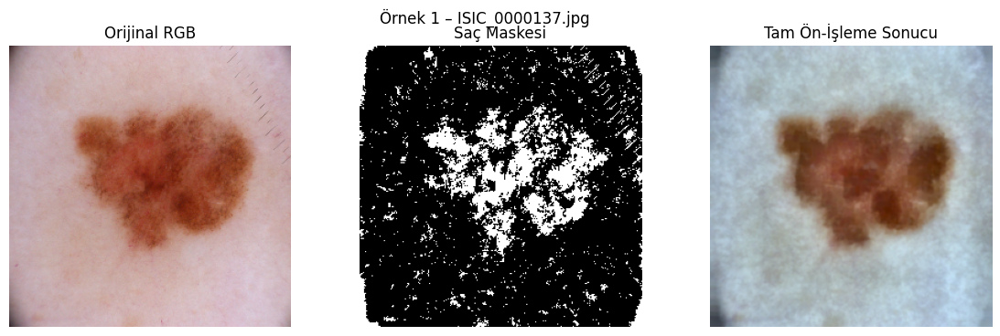

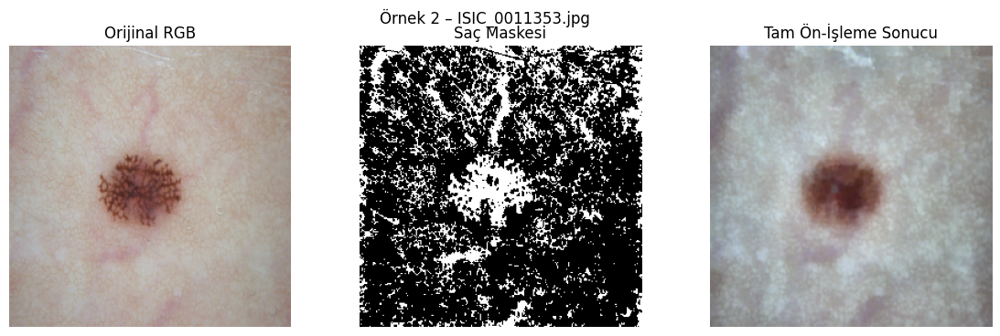

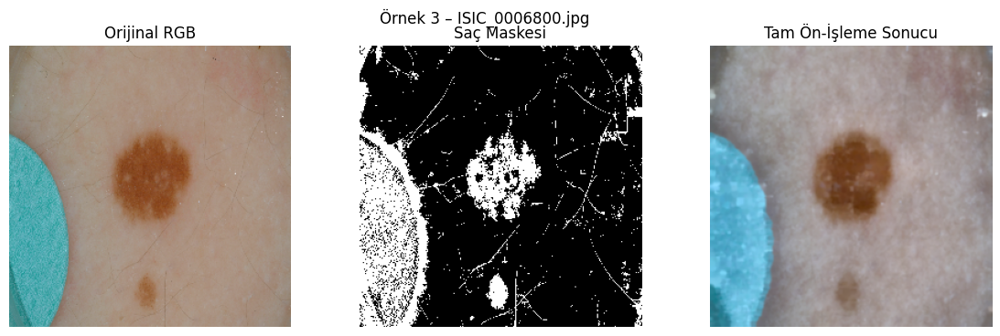

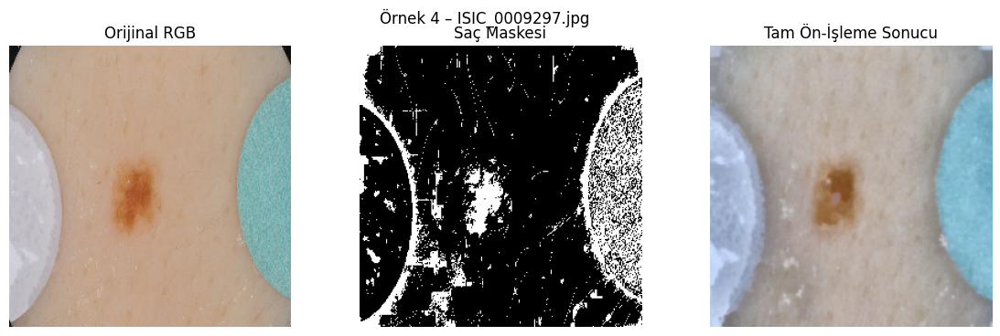

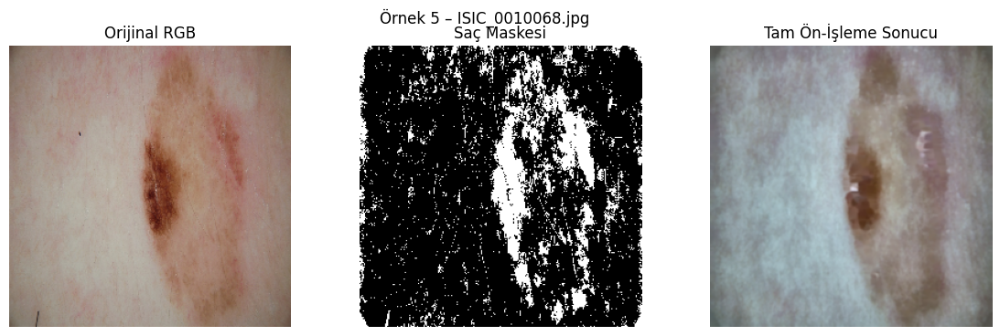

In [ ]:
# ============================================================
# PART 6 – GELİŞMİŞ ÖN-İŞLEME PIPELINE'I + 4–5 ÖRNEK
# ============================================================
# Bu partta:
# - Gray-World color constancy
# - Black-hat + inpainting ile saç giderme
# - Lab(L) kanalında CLAHE ile kontrast artırma
# - İsteğe bağlı Gaussian blur
# - Gamma düzeltmesi
# - [0,1] aralığına normalizasyon
#
# Çıktı:
#   img_pre  : ön-işlenmiş RGB [0,1] float32
#   hair_mask: tespit edilen saç maskesi (0/255)
# Ayrıca:
#   En altta train_pairs içinden 4–5 örnek için
#   Orijinal + saç maskesi + tam ön-işleme sonucu çizdiriyoruz.

def gray_world_color_constancy(img_rgb: np.ndarray) -> np.ndarray:
    """
    Basit Gray-World color constancy.
    img_rgb: RGB [0-255] uint8
    """
    img = img_rgb.astype(np.float32)

    # Her kanalın ortalama değeri
    mean_r = np.mean(img[:, :, 0])
    mean_g = np.mean(img[:, :, 1])
    mean_b = np.mean(img[:, :, 2])

    # Hedef gri ortalama
    mean_gray = (mean_r + mean_g + mean_b) / 3.0 + 1e-6

    # Her kanalı mean_gray'e yaklaştır
    scale_r = mean_gray / (mean_r + 1e-6)
    scale_g = mean_gray / (mean_g + 1e-6)
    scale_b = mean_gray / (mean_b + 1e-6)

    img[:, :, 0] *= scale_r
    img[:, :, 1] *= scale_g
    img[:, :, 2] *= scale_b

    img = np.clip(img, 0, 255).astype(np.uint8)
    return img

def remove_hair_blackhat_inpaint(
    img_rgb: np.ndarray,
    kernel_size: int = 17,
    thresh: int = 10,
    inpaint_radius: int = 1
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Black-hat + threshold + Telea inpainting ile saç giderme.

    img_rgb: RGB [0-255] uint8
    kernel_size: black-hat için kernel boyutu (tek sayı olmalı)
    thresh: black-hat çıktısını binarize ederken kullanılan eşik
    inpaint_radius: cv2.inpaint yarıçapı
    """
    # RGB -> GRAY
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    # Saç gibi ince koyu yapıları ortaya çıkarmak için black-hat
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_size, kernel_size))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)

    # Saç maskesi: blackhat yüksekse "saç" olarak işaretle
    _, hair_mask = cv2.threshold(blackhat, thresh, 255, cv2.THRESH_BINARY)

    # Inpainting için BGR gerekiyor
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)

    # Telea inpainting
    inpainted_bgr = cv2.inpaint(bgr, hair_mask, inpaint_radius, cv2.INPAINT_TELEA)

    # Tekrar RGB'ye dön
    inpainted_rgb = cv2.cvtColor(inpainted_bgr, cv2.COLOR_BGR2RGB)

    return inpainted_rgb, hair_mask

def apply_clahe_lab(
    img_rgb: np.ndarray,
    clip_limit: float = 2.0,
    tile_grid_size: Tuple[int, int] = (8, 8)
) -> np.ndarray:
    """Lab uzayında L kanalına CLAHE uygular ve tekrar RGB döner."""
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    L_clahe = clahe.apply(L)

    lab_clahe = cv2.merge((L_clahe, a, b))
    img_clahe_rgb = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    return img_clahe_rgb

def apply_gamma_correction(img_rgb_float: np.ndarray, gamma: float = 1.0) -> np.ndarray:
    """
    Gamma düzeltmesi (img_rgb_float: [0,1]).
    gamma < 1  -> görüntüyü aydınlatır
    gamma > 1  -> görüntüyü karartır
    gamma = 1  -> hiçbir şey yapmaz
    """
    if gamma <= 0:
        return img_rgb_float
    return np.power(img_rgb_float, 1.0 / gamma)

def preprocess_image_full(
    img_rgb_uint8: np.ndarray,
    use_color_constancy: bool = True,
    use_hair_removal: bool = True,
    clahe_clip_limit: float = 2.0,
    clahe_tile_grid: Tuple[int, int] = (8, 8),
    gaussian_ksize: int = 0,   # 0 veya 1 -> blur yok; >1 ve tek sayı -> blur
    gaussian_sigma: float = 0,
    gamma: float = 1.0
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Tam ön-işleme pipeline'ı:
    - (Opsiyonel) Gray-World color constancy
    - (Opsiyonel) Black-hat + inpainting ile saç giderme
    - Lab(L) üzerinde CLAHE
    - (Opsiyonel) Gaussian blur
    - Gamma düzeltmesi
    - [0,1] normalizasyon
    """
    # 1) Color constancy
    if use_color_constancy:
        img_proc = gray_world_color_constancy(img_rgb_uint8)
    else:
        img_proc = img_rgb_uint8.copy()

    # 2) Saç giderme
    if use_hair_removal:
        img_proc, hair_mask = remove_hair_blackhat_inpaint(img_proc)
    else:
        hair_mask = np.zeros(img_proc.shape[:2], dtype=np.uint8)

    # 3) CLAHE (Lab L kanalında)
    img_proc = apply_clahe_lab(
        img_proc,
        clip_limit=clahe_clip_limit,
        tile_grid_size=clahe_tile_grid
    )

    # 4) Gaussian blur (hafif gürültü azaltma, istenirse)
    if gaussian_ksize is not None and gaussian_ksize > 1:
        if gaussian_ksize % 2 == 0:
            gaussian_ksize += 1  # kernel tek sayı olmalı
        img_proc = cv2.GaussianBlur(img_proc, (gaussian_ksize, gaussian_ksize), gaussian_sigma)

    # 5) [0,1] normalizasyon
    img_proc = img_proc.astype(np.float32) / 255.0

    # 6) Gamma düzeltmesi
    img_proc = apply_gamma_correction(img_proc, gamma=gamma)

    # Güvenlik için [0,1] arasında tut
    img_proc = np.clip(img_proc, 0.0, 1.0).astype(np.float32)

    return img_proc, hair_mask

# ------------------------------------------------------------
# PART 6 – 4–5 ÖRNEKLİ GÖRSEL ÖN-İŞLEME DEMOSU
# ------------------------------------------------------------
# Burada:
# - train_pairs içinden  5 örnek alıyoruz
# - Her biri için:
#     Orijinal RGB
#     Saç maskesi
#     Tam ön-işleme sonucu
#   yan yana çiziliyor.

num_examples = min(5, len(train_pairs))
print(f"\nPART 6: Örnek olarak gösterilecek görüntü sayısı: {num_examples}")

for i in range(num_examples):
    img_path, msk_path = train_pairs[i]
    img_rgb = read_image(img_path)

    img_pre, hair_mask = preprocess_image_full(
        img_rgb,
        use_color_constancy=True,
        use_hair_removal=True,
        clahe_clip_limit=2.0,
        clahe_tile_grid=(8, 8),
        gaussian_ksize=3,
        gaussian_sigma=0,
        gamma=1.0
    )

    plt.figure(figsize=(14,4))
    plt.suptitle(f"Örnek {i+1} – {os.path.basename(img_path)}", fontsize=12)

    plt.subplot(1,3,1)
    plt.imshow(img_rgb)
    plt.title("Orijinal RGB")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(hair_mask, cmap="gray")
    plt.title("Saç Maskesi")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(img_pre)
    plt.title("Tam Ön-İşleme Sonucu")
    plt.axis("off")

    plt.show()


In [ ]:
# ============================================================
# PART 7 – KABA MASKE (THRESHOLD + MORFOLOJİ) – ARA ADIMLARLA
# ============================================================
# Bu partta:
# - Önce tam ön-işleme pipeline'ını (PART 6: preprocess_image_full) uygularız
# - Ön-işlenmiş görüntüden Lab a- veya b-kanalını çıkarırız
# - Otsu threshold (THRESHOLD)
# - Morfoloji (opening + closing) → THRESHOLD + MORFOLOJİ
# - Küçük bölgeleri atıp "kaba maske" üretiyoruz
# Fonksiyon ara adımları da döndürür ki görselleştirebilelim.

def classical_segmentation_with_steps(
    rgb_uint8: np.ndarray,
    lab_channel: str = "a",
    kernel_size: int = 5,
    min_size: int = 200
):
    """
    Classical coarse mask üretimi + ara adımlar (SUNUM İLE UYUMLU):

      0. Tam ön-işleme (PART 6: preprocess_image_full)
      1. Ön-işlenmiş görüntüden Lab uzayında kanal seç (a veya b)
      2. Otsu threshold -> otsu_mask
      3. Morphology (opening + closing) -> morph_mask
      4. Küçük bölgeleri temizle -> coarse_mask

    Girdi:
      rgb_uint8 : [0-255] uint8 RGB (H,W,3)

    Dönenler:
      coarse_mask : float32 [0,1] (H,W)
      otsu_mask   : uint8  0/255  (H,W)
      morph_mask  : uint8  0/255  (H,W)
    """

    # -----------------------------
    # 0) Tam ön-işleme (sunumdaki full pipeline)
    # -----------------------------
    img_pre, hair_mask = preprocess_image_full(
        img_rgb_uint8=rgb_uint8,
        use_color_constancy=True,
        use_hair_removal=True,
        clahe_clip_limit=2.0,
        clahe_tile_grid=(8, 8),
        gaussian_ksize=3,   # hafif blur
        gaussian_sigma=0,
        gamma=1.0
    )
    # img_pre: [0,1] float RGB
    img_pre_uint8 = (img_pre * 255).astype(np.uint8)

    # -----------------------------
    # 1) Lab uzayında kanal seçimi (a veya b)
    # -----------------------------
    lab = cv2.cvtColor(img_pre_uint8, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)

    if lab_channel == "a":
        gray = A
    elif lab_channel == "b":
        gray = B
    else:
        raise ValueError("lab_channel 'a' veya 'b' olmalı.")

    # -----------------------------
    # 2) Otsu threshold (THRESHOLD)
    # -----------------------------
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, otsu_mask = cv2.threshold(
        blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    # otsu_mask: 0/255 uint8

    # -----------------------------
    # 3) Morphology: opening + closing
    #    (THRESHOLD + MORFOLOJİ)
    # -----------------------------
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size)
    )

    opened     = cv2.morphologyEx(otsu_mask, cv2.MORPH_OPEN,  kernel)
    morph_mask = cv2.morphologyEx(opened,    cv2.MORPH_CLOSE, kernel)

    # -----------------------------
    # 4) Küçük bölgeleri temizle → KABA MASKE
    # -----------------------------
    num_labels, labels = cv2.connectedComponents(morph_mask)

    cleaned = np.zeros_like(morph_mask)
    for label in range(1, num_labels):
        region = (labels == label)
        if np.sum(region) >= min_size:
            cleaned[region] = 255

    coarse_mask = (cleaned > 127).astype(np.float32)  # 0/1

    return coarse_mask, otsu_mask, morph_mask



PART 8: 5'li karşılaştırma için kullanılacak örnek sayısı: 75


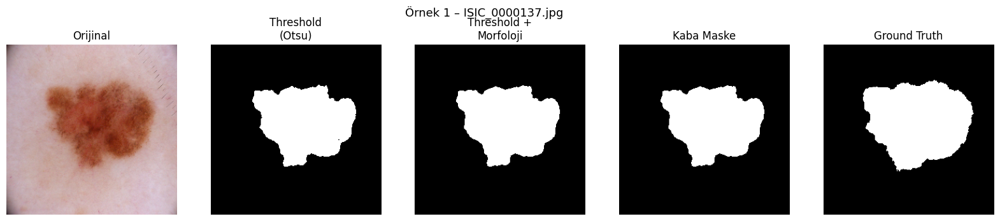

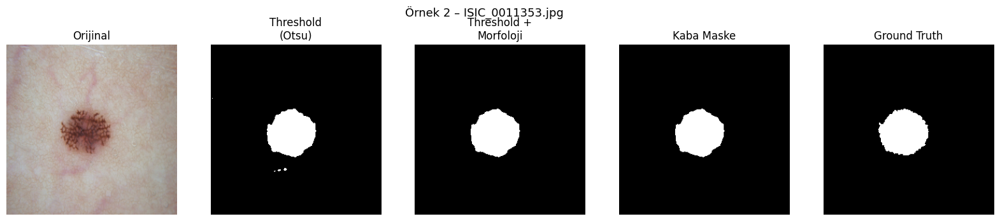

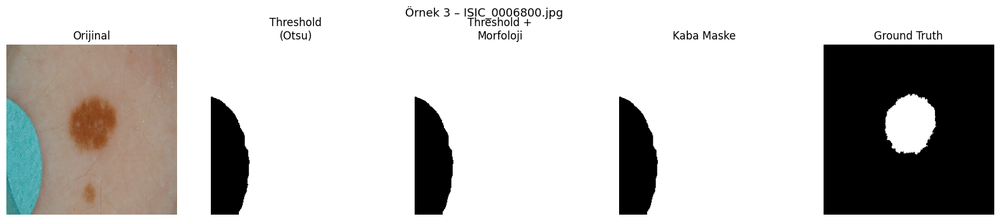

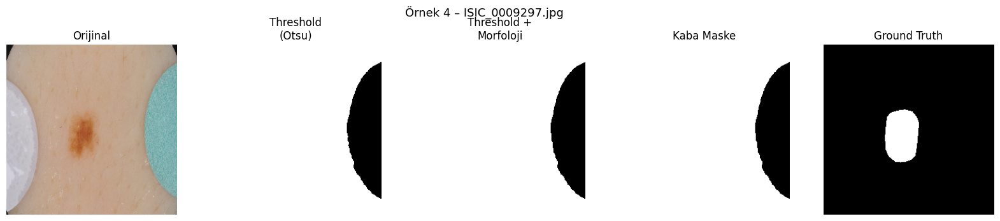

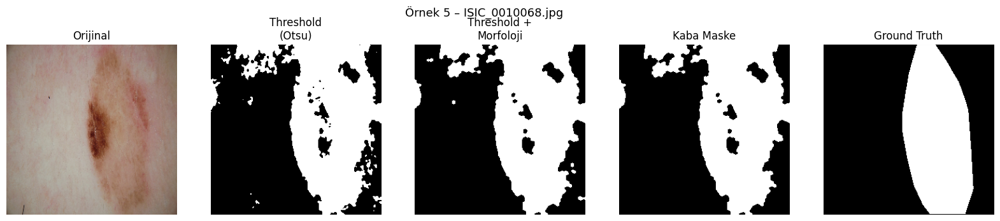

...

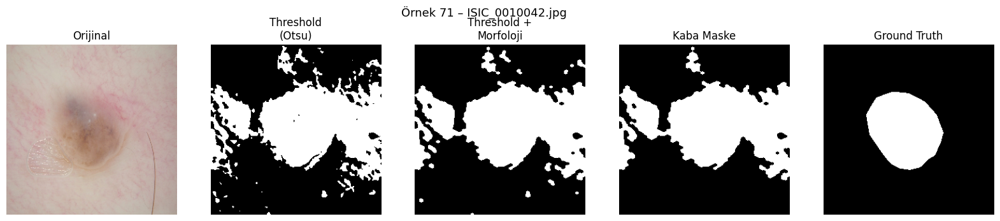

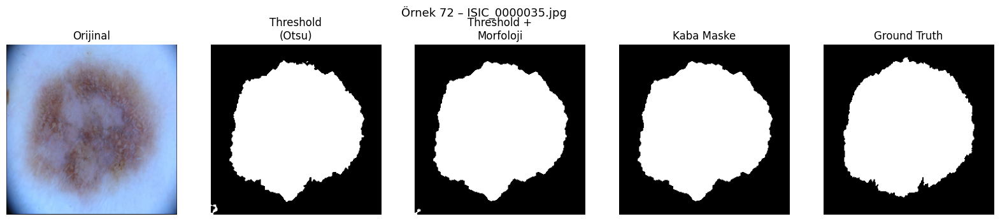

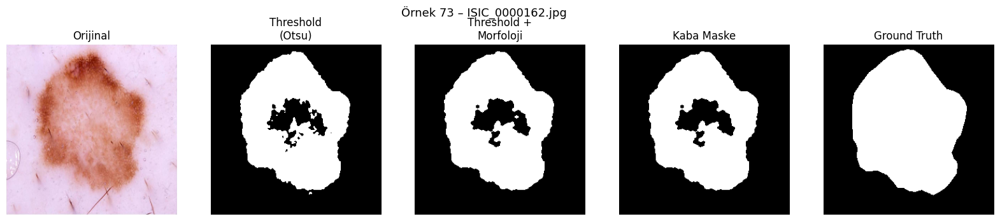

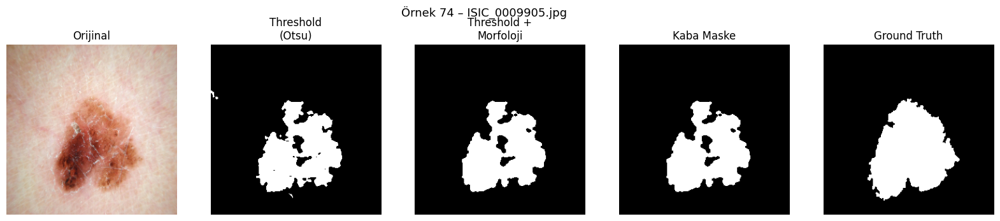

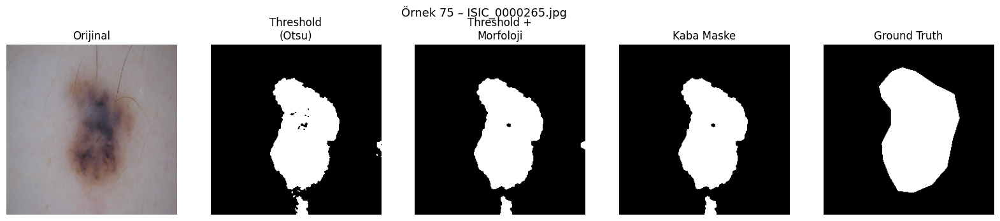

In [ ]:
# ============================================================
# PART 8 – 5'Lİ KARŞILAŞTIRMA:
#  Orijinal – Threshold – Thresh+Morph – Kaba Maske – Ground Truth
# ============================================================

num_examples = min(75, len(train_pairs))
print(f"\nPART 8: 5'li karşılaştırma için kullanılacak örnek sayısı: {num_examples}")

for i in range(num_examples):
    img_path, msk_path = train_pairs[i]

    # 1) Orijinal görüntü ve GT maskeyi oku
    img_rgb = read_image(img_path)
    gt_mask = read_mask(msk_path)       # 0/1 float

    # 2) Klasik segmentasyon + ara adımlar
    coarse_mask, otsu_mask, morph_mask = classical_segmentation_with_steps(
        img_rgb,
        lab_channel="a",     # istersen "b" ile de deneyebilirsin
        kernel_size=5,
        min_size=200
    )

    # 3) Plot
    plt.figure(figsize=(20,4))
    plt.suptitle(f"Örnek {i+1} – {os.path.basename(img_path)}", fontsize=13)

    # (1) Orijinal
    plt.subplot(1,5,1)
    plt.imshow(img_rgb)
    plt.title("Orijinal")
    plt.axis("off")

    # (2) Threshold (Otsu)
    plt.subplot(1,5,2)
    plt.imshow(otsu_mask, cmap="gray")
    plt.title("Threshold\n(Otsu)")
    plt.axis("off")

    # (3) Threshold + Morfoloji (open+close)
    plt.subplot(1,5,3)
    plt.imshow(morph_mask, cmap="gray")
    plt.title("Threshold +\nMorfoloji")
    plt.axis("off")

    # (4) Kaba Maske (küçük parçalar atılmış)
    plt.subplot(1,5,4)
    plt.imshow(coarse_mask, cmap="gray")
    plt.title("Kaba Maske")
    plt.axis("off")

    # (5) Ground Truth (doktorun maskesi)
    plt.subplot(1,5,5)
    plt.imshow(gt_mask, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.show()


In [ ]:
# ============================================================
# PART 9 – Klasik Segmentasyon Kalite Metrikleri
# ============================================================

from scipy.spatial.distance import directed_hausdorff

def dice_score(y_true, y_pred, smooth=1e-6):
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    inter = np.sum(y_true_f * y_pred_f)
    return (2 * inter + smooth) / (np.sum(y_true_f) + np.sum(y_pred_f) + smooth)

def iou_score(y_true, y_pred, smooth=1e-6):
    y_true_f = y_true.flatten()
    y_pred_f = y_pred.flatten()
    inter = np.sum(y_true_f * y_pred_f)
    union = np.sum(y_true_f) + np.sum(y_pred_f) - inter
    return (inter + smooth) / (union + smooth)

def accuracy_score(y_true, y_pred):
    return np.mean((y_true == y_pred).astype(np.float32))

def hd95(y_true, y_pred):
    """
    Hausdorff Distance 95%
    (Burada basitçe iki yönlü directed Hausdorff'un 95. yüzdelik değeri alınıyor.)
    """
    y_true_pts = np.argwhere(y_true > 0.5)
    y_pred_pts = np.argwhere(y_pred > 0.5)

    if len(y_true_pts) == 0 or len(y_pred_pts) == 0:
        return np.nan

    hd1 = directed_hausdorff(y_true_pts, y_pred_pts)[0]
    hd2 = directed_hausdorff(y_pred_pts, y_true_pts)[0]
    return np.percentile([hd1, hd2], 95)


# ------------------------------------------------------------
# classical_segmentation wrapper:
#   Girdi: rgb_norm (0-1 float), Çıkış: 0/1 maske
#   İçeride: bizim classical_segmentation_with_steps çağrılıyor.
# ------------------------------------------------------------

def classical_segmentation(rgb_norm,
                           lab_channel="a",
                           kernel_size=5,
                           min_size=200):
    """
    rgb_norm: [0,1] float RGB (H,W,3)
    Çıktı: 0/1 float32 maske (H,W)
    """
    rgb_uint8 = (rgb_norm * 255).astype(np.uint8)
    coarse_mask, _, _ = classical_segmentation_with_steps(
        rgb_uint8,
        lab_channel=lab_channel,
        kernel_size=kernel_size,
        min_size=min_size
    )
    return coarse_mask


# ------------------------------------------------------------
# 9.1 – Tüm validation set üzerinde "final klasik yöntem" performansı
# ------------------------------------------------------------

def evaluate_classical_on_dataset(pair_list, max_samples=None):
    """
    Final klasik yöntemi (classical_segmentation) tüm set üzerinde test eder.
    Girdi/çıktı:
      - pair_list: (img_path, mask_path) listesi
      - mask'ler 0/1 float
    """
    dice_list, iou_list, acc_list, hd_list = [], [], [], []

    if max_samples is not None:
        pair_list = pair_list[:max_samples]

    for img_path, mask_path in pair_list:
        rgb  = read_image(img_path)   # uint8
        m_gt = read_mask(mask_path)   # 0/1 float

        # Burada klasik yöntem için basit preprocess kullanıyoruz
        rgb_p  = preprocess_rgb(rgb)          # 0-1 float RGB
        gt     = preprocess_mask(m_gt)        # 0-1 float
        pred   = classical_segmentation(rgb_p)

        dice_list.append(dice_score(gt, pred))
        iou_list.append(iou_score(gt, pred))
        acc_list.append(accuracy_score(gt, pred))
        hd_list.append(hd95(gt, pred))

    return {
        "Dice_mean": np.nanmean(dice_list),
        "IoU_mean":  np.nanmean(iou_list),
        "Acc_mean":  np.nanmean(acc_list),
        "HD95_mean": np.nanmean(hd_list),
        "Dice_std":  np.nanstd(dice_list),
        "IoU_std":   np.nanstd(iou_list),
        "Acc_std":   np.nanstd(acc_list),
        "HD95_std":  np.nanstd(hd_list),
    }

print("\nKlasik Segmentasyon – Validation Set Sonuçları:")
classic_val_results = evaluate_classical_on_dataset(val_pairs)
classic_val_results



Klasik Segmentasyon – Validation Set Sonuçları:


{'Dice_mean': np.float32(0.71144336),
 'IoU_mean': np.float32(0.60018617),
 'Acc_mean': np.float32(0.8197208),
 'HD95_mean': np.float64(58.77346966122427),
 'Dice_std': np.float32(0.24629673),
 'IoU_std': np.float32(0.25500575),
 'Acc_std': np.float32(0.21641797),
 'HD95_std': np.float64(52.932239058482054)}

In [ ]:
# ============================================================
# PART 10 – Threshold, Threshold+Morphology, Coarse Classical Karşılaştırması
# ============================================================

def classic_threshold(rgb_norm):
    """
    Sadece LAB-a kanalı + adaptif threshold (inverse).
    Girdi: rgb_norm [0,1] float RGB
    Çıktı: 0/1 float maske
    """
    rgb_uint8 = (rgb_norm * 255).astype(np.uint8)
    bgr = cv2.cvtColor(rgb_uint8, cv2.COLOR_RGB2BGR)
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)

    th = cv2.adaptiveThreshold(
        a, 255,
        cv2.ADAPTIVE_THRESH_MEAN_C,
        cv2.THRESH_BINARY_INV,
        21, 5
    )
    return (th > 127).astype(np.float32)


def classic_threshold_morph(rgb_norm):
    """
    Threshold + morfoloji (open+close).
    Girdi: rgb_norm [0,1] float RGB
    Çıktı: 0/1 float maske
    """
    mask = classic_threshold(rgb_norm)

    mask_uint8 = (mask * 255).astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5,5))
    opened = cv2.morphologyEx(mask_uint8, cv2.MORPH_OPEN, kernel)
    closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)
    return (closed > 127).astype(np.float32)


def evaluate_method_on_dataset(method_fn, pair_list, max_samples=None):
    """
    Verilen klasik yöntemin (method_fn) performansını set üzerinde ölçer.
    method_fn: rgb_norm (0-1 float RGB) -> 0/1 float maske
    """
    dice_list, iou_list, acc_list, hd_list = [], [], [], []

    if max_samples is not None:
        pair_list = pair_list[:max_samples]

    for img_path, mask_path in pair_list:
        rgb  = read_image(img_path)
        m_gt = read_mask(mask_path)

        rgb_p = preprocess_rgb(rgb)       # 0-1 float RGB
        gt    = preprocess_mask(m_gt)     # 0-1 float

        pred  = method_fn(rgb_p)

        dice_list.append(dice_score(gt, pred))
        iou_list.append(iou_score(gt, pred))
        acc_list.append(accuracy_score(gt, pred))
        hd_list.append(hd95(gt, pred))

    return {
        "Dice": np.nanmean(dice_list),
        "IoU":  np.nanmean(iou_list),
        "Acc":  np.nanmean(acc_list),
        "HD95": np.nanmean(hd_list)
    }

print("\n=== Klasik 3 Yöntemin Karşılaştırması (Validation Set) ===")

results_threshold = evaluate_method_on_dataset(classic_threshold, val_pairs)
results_thresh_morph = evaluate_method_on_dataset(classic_threshold_morph, val_pairs)
results_coarse = evaluate_method_on_dataset(classical_segmentation, val_pairs)

print("\n--- Sadece Threshold ---")
print(results_threshold)

print("\n--- Threshold + Morfoloji ---")
print(results_thresh_morph)

print("\n--- Final Coarse Classical  ---")
print(results_coarse)



=== Klasik 3 Yöntemin Karşılaştırması (Validation Set) ===

--- Sadece Threshold ---
{'Dice': np.float32(0.011800839), 'IoU': np.float32(0.006050029), 'Acc': np.float32(0.7329088), 'HD95': np.float64(88.2446217377156)}

--- Threshold + Morfoloji ---
{'Dice': np.float32(0.003268793), 'IoU': np.float32(0.0016548006), 'Acc': np.float32(0.7328204), 'HD95': np.float64(117.536459850524)}

--- Final Coarse Classical  ---
{'Dice': np.float32(0.71144336), 'IoU': np.float32(0.60018617), 'Acc': np.float32(0.8197208), 'HD95': np.float64(58.77346966122427)}


In [ ]:
# ============================================================
# 11-KABA MASKE → KLİNİK ŞEKİL ÖZELLİKLERİ
# ============================================================

import os
import numpy as np
import cv2

from skimage import measure
from skimage.morphology import convex_hull_image
from skimage.measure import perimeter as sk_perimeter

# ------------------------------------------------------------
# 1) En büyük komponenti seç + yardımcı fonksiyonlar
# ------------------------------------------------------------

def _get_main_region(mask_bin):
    """
    Maske içinde en büyük connected component'i bulur.
    mask_bin: 0/1 veya bool (H,W)
    Dönen:
      main_mask: 0/1 uint8, sadece en büyük bölge
      region   : skimage.regionprops objesi (None olabilir)
    """
    mask_bin = (mask_bin > 0.5).astype(np.uint8)
    labeled = measure.label(mask_bin, connectivity=2)

    if labeled.max() == 0:
        return mask_bin.astype(np.uint8), None

    props = measure.regionprops(labeled)
    largest = max(props, key=lambda r: r.area)
    main_mask = (labeled == largest.label).astype(np.uint8)
    return main_mask, largest


def _compute_asymmetry_indices(mask_bin):
    """
    Dikey ve yatay asimetri indeksleri.
    Mask boşsa hepsi NaN döner.
    Asym = |Area_left - Area_right| / (Area_left + Area_right)
    """
    mask = (mask_bin > 0.5).astype(np.uint8)

    # Maskede hiç piksel yoksa -> NaN
    if mask.sum() == 0:
        return np.nan, np.nan, np.nan

    h, w = mask.shape

    # --- Dikey asimetri (sol-sağ) ---
    mid_col = w // 2
    left  = mask[:, :mid_col]
    right = mask[:, mid_col:]

    right_flipped = np.fliplr(right)

    min_w = min(left.shape[1], right_flipped.shape[1])
    left  = left[:, :min_w]
    right_flipped = right_flipped[:, :min_w]

    area_left  = float(left.sum())
    area_right = float(right_flipped.sum())
    denom_lr   = max(area_left + area_right, 1.0)
    asym_vert  = abs(area_left - area_right) / denom_lr

    # --- Yatay asimetri (üst-alt) ---
    mid_row = h // 2
    top    = mask[:mid_row, :]
    bottom = mask[mid_row:, :]

    bottom_flipped = np.flipud(bottom)

    min_h = min(top.shape[0], bottom_flipped.shape[0])
    top           = top[:min_h, :]
    bottom_flipped = bottom_flipped[:min_h, :]

    area_top    = float(top.sum())
    area_bottom = float(bottom_flipped.sum())
    denom_tb    = max(area_top + area_bottom, 1.0)
    asym_horiz  = abs(area_top - area_bottom) / denom_tb

    asym_mean = (asym_vert + asym_horiz) / 2.0

    return asym_vert, asym_horiz, asym_mean


def _compute_radial_stats(main_mask, region):
    """
    Kontur noktalarının centroid'e olan uzaklıklarının
    ortalaması / varyansı / std'sini hesaplar.
    """
    mask = main_mask.astype(np.uint8)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)

    if len(contours) == 0:
        return np.nan, np.nan, np.nan

    cnt = max(contours, key=cv2.contourArea)
    coords = cnt[:, 0, :]  # (N, 2) -> (x, y)

    cy, cx = region.centroid  # (row, col)
    dx = coords[:, 0] - cx
    dy = coords[:, 1] - cy
    dist = np.sqrt(dx**2 + dy**2)

    return float(dist.mean()), float(dist.var()), float(dist.std())


# ------------------------------------------------------------
# 2) Tek maske için klinik şekil özellikleri
# ------------------------------------------------------------

def compute_clinical_shape_features(mask_bin):
    """
    Girdi:  mask_bin (0/1 float veya bool, HxW)
    Çıktı:  klinik şekil özellikleri sözlüğü (dict)
    """
    main_mask, region = _get_main_region(mask_bin)

    if region is None or region.area == 0:
        return {
            "area_px": np.nan,
            "perimeter_px": np.nan,
            "compactness": np.nan,
            "solidity": np.nan,
            "eccentricity": np.nan,
            "major_axis_length": np.nan,
            "minor_axis_length": np.nan,
            "convex_area": np.nan,
            "convexity": np.nan,
            "border_irregularity": np.nan,
            "asymmetry_vertical": np.nan,
            "asymmetry_horizontal": np.nan,
            "asymmetry_mean": np.nan,
            "radial_mean": np.nan,
            "radial_var": np.nan,
            "radial_std": np.nan,
        }

    area = float(region.area)

    # sk_perimeter'da keyword parametresi yok, varsayılanı kullanıyoruz
    perim = float(sk_perimeter(main_mask))
    convex_area = float(region.convex_area)
    solidity = float(region.solidity)
    ecc = float(region.eccentricity)
    maj = float(region.major_axis_length)
    minr = float(region.minor_axis_length)

    if perim > 0:
        compactness = 4.0 * np.pi * area / (perim**2 + 1e-8)
        border_irregularity = (perim**2) / (4.0 * np.pi * area + 1e-8)
    else:
        compactness = np.nan
        border_irregularity = np.nan

    chull = convex_hull_image(main_mask)
    chull_perim = float(sk_perimeter(chull)) if perim > 0 else np.nan

    if perim > 0:
        convexity = chull_perim / perim
    else:
        convexity = np.nan

    asym_v, asym_h, asym_m = _compute_asymmetry_indices(main_mask)
    radial_mean, radial_var, radial_std = _compute_radial_stats(main_mask, region)

    features = {
        "area_px": area,
        "perimeter_px": perim,
        "compactness": compactness,
        "solidity": solidity,
        "eccentricity": ecc,
        "major_axis_length": maj,
        "minor_axis_length": minr,
        "convex_area": convex_area,
        "convexity": convexity,
        "border_irregularity": border_irregularity,
        "asymmetry_vertical": asym_v,
        "asymmetry_horizontal": asym_h,
        "asymmetry_mean": asym_m,
        "radial_mean": radial_mean,
        "radial_var": radial_var,
        "radial_std": radial_std,
    }

    return features


# ------------------------------------------------------------
# 3) Kaba maske üreten wrapper (classical_segmentation)
#    NOT: classical_segmentation_with_steps daha önce tanımlı olmalı!
# ------------------------------------------------------------

def classical_segmentation(rgb_norm,
                           lab_channel="a",
                           kernel_size=5,
                           min_size=200):
    """
    rgb_norm: [0,1] float RGB (H,W,3)
    Çıktı: 0/1 float32 kaba maske (H,W)
    """
    rgb_uint8 = (rgb_norm * 255).astype(np.uint8)
    coarse_mask, _, _ = classical_segmentation_with_steps(
        rgb_uint8,
        lab_channel=lab_channel,
        kernel_size=kernel_size,
        min_size=min_size
    )
    return coarse_mask


# ------------------------------------------------------------
# 4) Dataset üzerinde: KABA MASKELER için klinik şekil özellikleri
# ------------------------------------------------------------

def extract_clinical_features_for_dataset_coarse(pair_list,
                                                 max_samples=None,
                                                 lab_channel="a",
                                                 kernel_size=5,
                                                 min_size=200):
    """
    Kaba maskeler (classical_segmentation) üzerinden klinik shape features çıkar.

    pair_list  : [(img_path, msk_path), ...]
    max_samples: istersen ilk N örneği kullan
    """
    features_all = []

    if max_samples is not None:
        pair_list = pair_list[:max_samples]

    for idx, (img_path, msk_path) in enumerate(pair_list):
        # 1) Görüntüyü oku ve klasik pipeline için ön işle
        rgb   = read_image(img_path)         # uint8
        rgb_p = preprocess_rgb(rgb)          # 0-1 float RGB

        # 2) Kaba maske üret (0/1 float)
        coarse_mask = classical_segmentation(
            rgb_p,
            lab_channel=lab_channel,
            kernel_size=kernel_size,
            min_size=min_size
        )

        # 3) Klinik şekil özelliklerini hesapla
        feats = compute_clinical_shape_features(coarse_mask)
        feats["image_name"] = os.path.basename(img_path)
        feats["mask_type"]  = "COARSE"

        features_all.append(feats)

    return features_all


# ------------------------------------------------------------
# 5) ÖRNEK KULLANIM:
# ------------------------------------------------------------

coarse_feats_val10 = extract_clinical_features_for_dataset_coarse(val_pairs, max_samples=10)

# İlk 2 örneğin sonuçlarını yazdır (kontrol amaçlı)
for row in coarse_feats_val10[:2]:
    print("Image:", row["image_name"], "| Mask type:", row["mask_type"])
    for k, v in row.items():
        if k not in ["image_name", "mask_type"]:
            print(f"  {k}: {v}")
    print("--------------")


Image: ISIC_0010339.jpg | Mask type: COARSE
  area_px: 4712.0
  perimeter_px: 291.4213562373095
  compactness: 0.6972241086881362
  solidity: 0.9140640155189137
  eccentricity: 0.3068711953694465
  major_axis_length: 80.59102897991197
  minor_axis_length: 76.70259680262131
  convex_area: 5155.0
  convexity: 0.931227996399748
  border_irregularity: 1.4342590675489777
  asymmetry_vertical: 0.1099320882852292
  asymmetry_horizontal: 0.08191850594227504
  asymmetry_mean: 0.09592529711375211
  radial_mean: 38.40671262366941
  radial_var: 12.038397472528032
  radial_std: 3.469639386525354
--------------
Image: ISIC_0001133.jpg | Mask type: COARSE
  area_px: 10107.0
  perimeter_px: 672.541197284454
  compactness: 0.2807982160467568
  solidity: 0.8108303249097473
  eccentricity: 0.40340666419083776
  major_axis_length: 125.78579199437918
  minor_axis_length: 115.09661594054637
  convex_area: 12465.0
  convexity: 0.6332539856122945
  border_irregularity: 3.5612761864319866
  asymmetry_vertical:

In [ ]:
#PART 12 – Keras Sequence (HYBRID için, hızlı)
import numpy as np
import random
from tensorflow.keras.utils import Sequence

# Notebook'undaki classical_segmentation parametreleriyle uyumlu default
DEFAULT_CLASSICAL_PARAMS = {
    "lab_channel": "a",
    "kernel_size": 5,
    "min_size": 200
}

class SegmentationSequence(Sequence):
    def __init__(self, pairs, batch_size=8, hybrid=False, shuffle=True, classical_params=None):
        self.pairs = list(pairs)  # güvenli kopya
        self.batch_size = batch_size
        self.hybrid = hybrid
        self.shuffle = shuffle
        self.classical_params = classical_params or DEFAULT_CLASSICAL_PARAMS
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.pairs) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            random.shuffle(self.pairs)

    def __getitem__(self, idx):
        batch_pairs = self.pairs[idx * self.batch_size : (idx + 1) * self.batch_size]

        X_list, Y_list = [], []

        for img_path, mask_path in batch_pairs:
            rgb_uint8 = read_image(img_path)     # (H,W,3) uint8
            m_gt      = read_mask(mask_path)     # (H,W)   float 0/1

            rgb_p  = preprocess_rgb(rgb_uint8)   # (H,W,3) float [0,1]
            mask_p = preprocess_mask(m_gt)       # (H,W)   float 0/1

            if self.hybrid:
                #  Notebook uyumlu çağrı: classical_segmentation(rgb_norm, **params)
                coarse = classical_segmentation(rgb_p, **self.classical_params)  # (H,W) float 0/1
                coarse = coarse[..., np.newaxis]                                 # (H,W,1)
                x = np.concatenate([rgb_p, coarse], axis=-1)                     # (H,W,4)
            else:
                x = rgb_p  # (H,W,3)

            X_list.append(x.astype(np.float32))
            Y_list.append(mask_p[..., np.newaxis].astype(np.float32))  # (H,W,1)

        X = np.stack(X_list, axis=0)
        Y = np.stack(Y_list, axis=0)
        return X, Y


# SADECE HYBRID DATA LOADER (senin sevdiğin gibi)
BATCH_SIZE = 8

train_seq_hybrid = SegmentationSequence(
    train_pairs, batch_size=BATCH_SIZE, hybrid=True, shuffle=True,
    classical_params=DEFAULT_CLASSICAL_PARAMS
)

val_seq_hybrid = SegmentationSequence(
    val_pairs, batch_size=BATCH_SIZE, hybrid=True, shuffle=False,
    classical_params=DEFAULT_CLASSICAL_PARAMS
)


In [ ]:
#PART 13 – U-Net modeli (Hybrid için 4 kanal)
import tensorflow as tf
from tensorflow.keras import layers, models

def conv_block(x, filters):
    x = layers.Conv2D(filters, (3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, (3,3), padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def build_unet(input_channels=4):
    inputs = layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, input_channels))

    c1 = conv_block(inputs, 32);  p1 = layers.MaxPool2D()(c1)
    c2 = conv_block(p1, 64);      p2 = layers.MaxPool2D()(c2)
    c3 = conv_block(p2, 128);     p3 = layers.MaxPool2D()(c3)
    c4 = conv_block(p3, 256);     p4 = layers.MaxPool2D()(c4)

    bn = conv_block(p4, 512)

    u4 = layers.UpSampling2D()(bn); u4 = layers.Concatenate()([u4, c4])
    c5 = conv_block(u4, 256)

    u3 = layers.UpSampling2D()(c5); u3 = layers.Concatenate()([u3, c3])
    c6 = conv_block(u3, 128)

    u2 = layers.UpSampling2D()(c6); u2 = layers.Concatenate()([u2, c2])
    c7 = conv_block(u2, 64)

    u1 = layers.UpSampling2D()(c7); u1 = layers.Concatenate()([u1, c1])
    c8 = conv_block(u1, 32)

    outputs = layers.Conv2D(1, (1,1), activation="sigmoid")(c8)
    return models.Model(inputs, outputs, name="Hybrid_UNet")

model_hybrid = build_unet(input_channels=4)
model_hybrid.summary()


Model: "Hybrid_UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │      1,184 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        512 │ conv2d_4[0][0]  

 Total params: 7,858,721 (29.98 MB)

 Trainable params: 7,852,833 (29.96 MB)

 Non-trainable params: 5,888 (23.00 KB)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - acc: 0.8670 - dice_coef: 0.6151 - loss: 0.7427 
Epoch 1: val_dice_coef improved from -inf to 0.20723, saving model to best_unet_hybrid.keras
79/79 ━━━━━━━━━━━━━━━━━━━━ 1967s 25s/step - acc: 0.8671 - dice_coef: 0.6157 - loss: 0.7416 - val_acc: 0.7334 - val_dice_coef: 0.2072 - val_loss: 1.3978 - learning_rate: 3.0000e-04
Epoch 2/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - acc: 0.8951 - dice_coef: 0.7176 - loss: 0.5583 
Epoch 2: val_dice_coef did not improve from 0.20723
79/79 ━━━━━━━━━━━━━━━━━━━━ 1943s 25s/step - acc: 0.8951 - dice_coef: 0.7177 - loss: 0.5580 - val_acc: 0.7334 - val_dice_coef: 0.1646 - val_loss: 1.4913 - learning_rate: 3.0000e-04
Epoch 3/20
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 23s/step - acc: 0.9083 - dice_coef: 0.7573 - loss: 0.4825 
Epoch 3: val_dice_coef did not improve from 0.20723

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
79/79 ━━━━━━━━━━━━━━━━━━━━ 1975s 25s/step - acc: 0.9082 - dice_coe

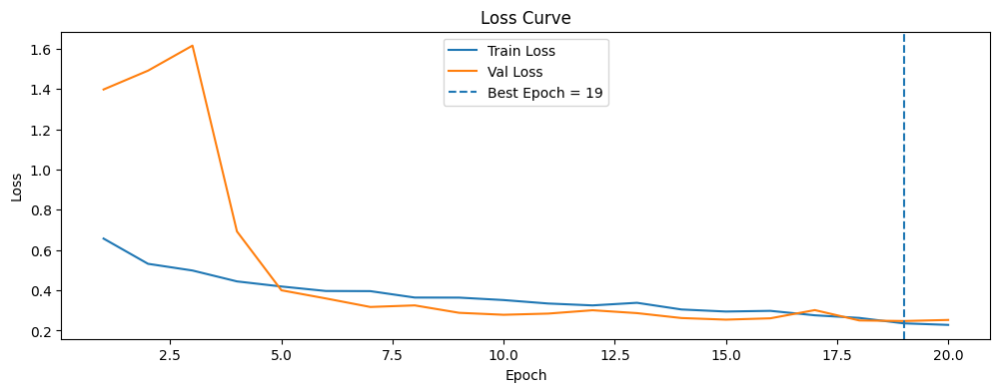

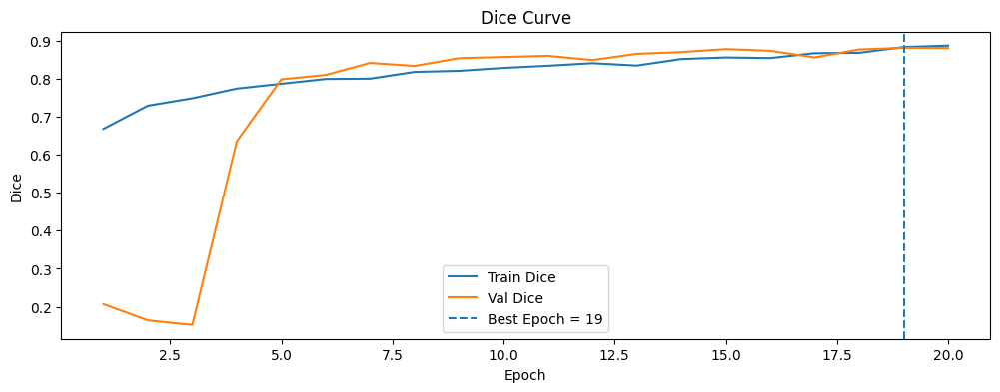

✅ Best model yüklendi: best_unet_hybrid.keras
---- VAL örnek ----


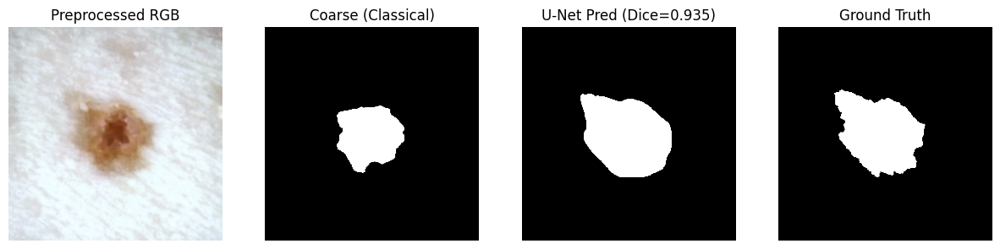

In [ ]:
# ============================================================
# PART 14+8 – HYBRID U-NET: EĞİTİM + SONUÇ ÖZETİ + GRAFİK + ÖRNEK ÇIKTI
# (Bunu model ve sequence'lerden SONRA tek hücre olarak çalıştır)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# -------------------------------
# 0) Loss / Metric
# -------------------------------
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

bce = tf.keras.losses.BinaryCrossentropy()

def bce_dice_loss(y_true, y_pred):
    return bce(y_true, y_pred) + dice_loss(y_true, y_pred)

METRICS = [
    tf.keras.metrics.BinaryAccuracy(name="acc"),
    dice_coef
]

def compile_model(model):
    optimizer = tf.keras.optimizers.Adam(learning_rate=3e-4)
    model.compile(optimizer=optimizer, loss=bce_dice_loss, metrics=METRICS)

compile_model(model_hybrid)

# -------------------------------
# 1) Callback'lar
# -------------------------------
BEST_PATH = "best_unet_hybrid.keras"

checkpoint_hybrid = tf.keras.callbacks.ModelCheckpoint(
    BEST_PATH,
    monitor="val_dice_coef",
    mode="max",
    save_best_only=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_dice_coef",
    mode="max",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

earlystop = tf.keras.callbacks.EarlyStopping(
    monitor="val_dice_coef",
    mode="max",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# -------------------------------
# 2) Eğitim
# -------------------------------
EPOCHS = 20

history_hybrid = model_hybrid.fit(
    train_seq_hybrid,
    validation_data=val_seq_hybrid,
    epochs=EPOCHS,
    callbacks=[checkpoint_hybrid, reduce_lr, earlystop],
    verbose=1
)

# -------------------------------
# 3) Eğitim Sonuç Özeti (Best epoch)
# -------------------------------
hist = history_hybrid.history

best_epoch = int(np.argmax(hist["val_dice_coef"]))  # 0-based
best_dice  = float(hist["val_dice_coef"][best_epoch])
best_acc   = float(hist["val_acc"][best_epoch])
best_loss  = float(hist["val_loss"][best_epoch])

print("\n================ HYBRID MODEL – EĞİTİM SONUÇ ÖZETİ ================\n")
print(f"En iyi epoch       : {best_epoch + 1}")
print(f"Best Val Dice      : {best_dice:.4f}")
print(f"Best Val Accuracy  : {best_acc:.4f}")
print(f"Best Val Loss      : {best_loss:.4f}")
print("\n====================================================================\n")

# -------------------------------
# 4) Grafikler: Loss & Dice
# -------------------------------
epochs = np.arange(1, len(hist["loss"]) + 1)

plt.figure(figsize=(12,4))
plt.plot(epochs, hist["loss"], label="Train Loss")
plt.plot(epochs, hist["val_loss"], label="Val Loss")
plt.axvline(best_epoch + 1, linestyle="--", label=f"Best Epoch = {best_epoch+1}")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.figure(figsize=(12,4))
plt.plot(epochs, hist["dice_coef"], label="Train Dice")
plt.plot(epochs, hist["val_dice_coef"], label="Val Dice")
plt.axvline(best_epoch + 1, linestyle="--", label=f"Best Epoch = {best_epoch+1}")
plt.title("Dice Curve")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.legend()
plt.show()

# -------------------------------
# 5) En iyi modeli yükle (Checkpoint)
# -------------------------------
try:
    best_model = tf.keras.models.load_model(
        BEST_PATH,
        custom_objects={"dice_coef": dice_coef, "bce_dice_loss": bce_dice_loss}
    )
    print("✅ Best model yüklendi:", BEST_PATH)
except Exception as e:
    print("⚠️ Best model yüklenemedi, mevcut model kullanılacak. Hata:", e)
    best_model = model_hybrid

# -------------------------------
# 6) Val/Test'ten örnek: RGB / Coarse / Pred / GT (4'lü)
# -------------------------------
def show_sample_from_pairs(pairs, idx=0, threshold=0.5, classical_params=None):
    classical_params = classical_params or DEFAULT_CLASSICAL_PARAMS

    img_path, mask_path = pairs[idx]
    rgb_uint8 = read_image(img_path)
    gt        = read_mask(mask_path)

    rgb_p = preprocess_rgb(rgb_uint8)   # (H,W,3)
    gt_p  = preprocess_mask(gt)         # (H,W)

    coarse = classical_segmentation(rgb_p, **classical_params)  # (H,W)

    x = np.concatenate([rgb_p, coarse[..., None]], axis=-1).astype(np.float32)  # (H,W,4)

    pred = best_model.predict(x[None, ...], verbose=0)[0, ..., 0]
    pred_bin = (pred > threshold).astype(np.uint8)

    # Dice (tek örnek)
    inter = np.sum(pred_bin * gt_p)
    denom = np.sum(pred_bin) + np.sum(gt_p) + 1e-6
    dice_one = (2.0 * inter) / denom

    plt.figure(figsize=(15,4))

    plt.subplot(1,4,1)
    plt.imshow(rgb_p)
    plt.title("Preprocessed RGB")
    plt.axis("off")

    plt.subplot(1,4,2)
    plt.imshow(coarse, cmap="gray")
    plt.title("Coarse (Classical)")
    plt.axis("off")

    plt.subplot(1,4,3)
    plt.imshow(pred_bin, cmap="gray")
    plt.title(f"U-Net Pred (Dice={dice_one:.3f})")
    plt.axis("off")

    plt.subplot(1,4,4)
    plt.imshow(gt_p, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.show()

print("---- VAL örnek ----")
show_sample_from_pairs(val_pairs, idx=0)

# İstersen testten de göstermek için:
# print("---- TEST örnek ----")
# show_sample_from_pairs(test_pairs, idx=0)
